# 02. Nettoyage et construction de la base

Sentinelle Scolaire, défi 1 : cartographie et anticipation du risque de décrochage scolaire.

Cette étape transforme les extractions brutes de l'étape 01 en une base unique, contrôlée et documentée :

- un **référentiel géographique** qui relie l'ancien découpage (13 régions, 45 provinces), utilisé par toutes les données DGESS, et le découpage de juillet 2025 (17 régions, 47 provinces), par l'intermédiaire des 351 communes ;
- des **tables de faits** en format long : taux de flux publiés, effectifs et redoublants, écoles fermées et rouvertes (ST-ESU), personnes déplacées internes (CONASUR) ;
- des **métadonnées** : description des tables et dictionnaire des variables ;
- un **journal** de chaque correction et des **contrôles automatiques**.

La base est un GeoPackage (`data/02_nettoyage/sentinelle_scolaire.gpkg`), qui s'ouvre dans QGIS ; chaque table est aussi exportée en CSV. Le code est dans `src/sentinelle/nettoyage/`.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from sentinelle import cartes, config, indicateurs
from sentinelle.depots import exporter_nettoyage
from sentinelle.nettoyage import executer_nettoyage

pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#bdbcb6",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Exécution et contrôles automatiques

In [2]:
res = executer_nettoyage()
res["meta_controles"]

,controle,conforme,detail
0,completude_flux,True,45 à 45 provinces par année
1,completude_effectifs,True,45 à 45 provinces par année
2,coherence_sexes,True,0 lignes où garçons + filles diffère du total
3,repartition_filles_garcons_plausible,False,"provinces hors [0.8 ; 1.25] par année : 2007-2008 : 1, 2008-2009 : 12, 2009-2010 : 3, 2010-2011 : 1, 2011-2012 : 1, ..."
4,somme_provinces_egale_total_regional_annuaire,False,39 écarts > 0.5% sur 3236 comparaisons
5,somme_provinces_egale_total_regional_base_principale,False,38 écarts > 0.5% sur 390 comparaisons (édition 2024-2025)
6,somme_provinces_egale_total_national_base_principale,False,5 écarts > 0.5% sur 30 comparaisons (édition 2024-2025)
7,jointure_contours_flux,True,45 à 45 provinces sur 45 avec contour
8,jointure_contours_effectifs,True,45 à 45 provinces sur 45 avec contour
9,esu_somme_provinces_egale_total_primaire_publie,True,"12 tableaux sur 30 retrouvent le total publié à 5 % près (2021-11-30 fermes, 2021-11-30 rouverts, 2021-12-31 fermes,..."


Lecture des contrôles :

- complétude et jointure avec les contours : 45 provinces sur 45, pour chaque édition ;
- la somme des 45 provinces retrouve le total national publié dans la base principale, à moins de 1 % près ; les écarts régionaux viennent des révisions entre éditions et de l'anomalie de 2024-2025 décrite plus bas ;
- la répartition filles / garçons de l'annuaire 2024-2025 est invraisemblable pour 31 provinces : pour cette année, seul le total est utilisable.

## 2. Référentiel géographique

La commune est le pivot. Chaque commune COD-AB porte son P-code actuel et son ancien P-code ; les quatre et six premiers caractères de l'ancien code désignent l'ancienne région et l'ancienne province. Les couches de chaque niveau sont obtenues en regroupant les communes, ce qui garantit des limites identiques d'un niveau à l'autre.

In [3]:
pd.DataFrame({nom: {"entités": len(res[nom])} for nom in ["commune", "province", "region", "province_ancienne", "region_ancienne"]}).T

,entités
commune,351
province,47
region,17
province_ancienne,45
region_ancienne,13


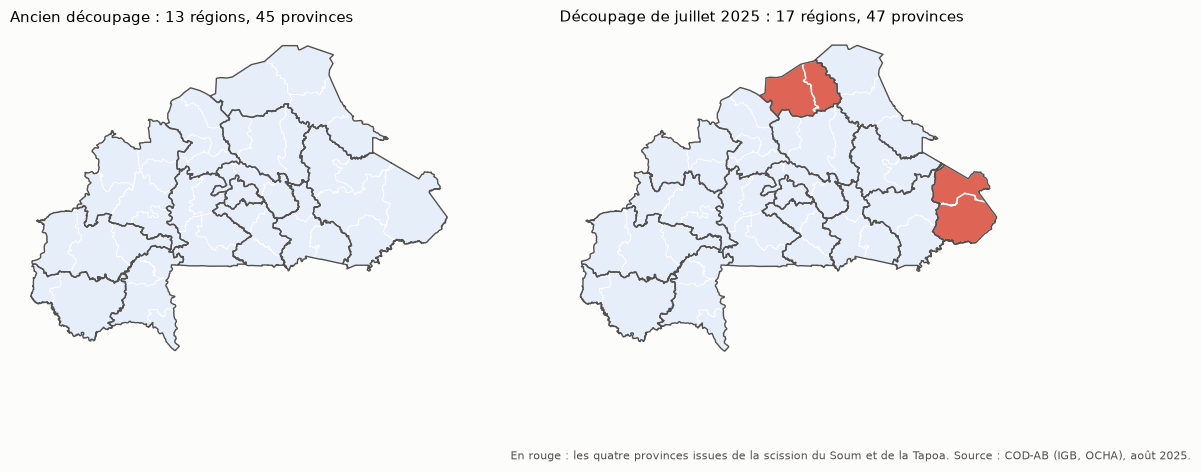

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (couche, titre) in zip(axes, [("province_ancienne", "Ancien découpage : 13 régions, 45 provinces"),
                                     ("province", "Découpage de juillet 2025 : 17 régions, 47 provinces")]):
    res[couche].plot(ax=ax, color="#e6eef9", edgecolor="#ffffff", linewidth=0.6)
    regions = res["region_ancienne" if couche == "province_ancienne" else "region"]
    regions.boundary.plot(ax=ax, color="#52514e", linewidth=1)
    if couche == "province":
        res["province"][res["province"]["province_ancienne_partagee"]].plot(ax=ax, color="#de6455", edgecolor="#ffffff")
    ax.set_title(titre, fontsize=11, loc="left"); ax.set_axis_off()
fig.text(0.51, 0.02, "En rouge : les quatre provinces issues de la scission du Soum et de la Tapoa. Source : COD-AB (IGB, OCHA), août 2025.",
         fontsize=8, color="#52514e")
plt.show()

In [5]:
res["province"].loc[res["province"]["province_ancienne_partagee"],
                    ["province_pcode", "province_nom", "region_nom", "province_ancienne_pcode", "province_ancienne_nom"]]

,province_pcode,province_nom,region_nom,province_ancienne_pcode,province_ancienne_nom
32,BF5901,Djelgodji,Soum,BF5603,Soum
33,BF5902,Karo-Peli,Soum,BF5603,Soum
34,BF6001,Dyamongou,Tapoa,BF5205,Tapoa
35,BF6002,Gobnangou,Tapoa,BF5205,Tapoa


In [6]:
res["contours_web"]

,niveau,fichier,taille_ko,points,nb_entites,geometries_valides,mosaique_valide
0,commune,commune.geojson,437.0,13559,351,True,True
1,province,province.geojson,132.9,5623,47,True,True
2,region,region.geojson,79.1,3635,17,True,True
3,province_ancienne,province_ancienne.geojson,126.5,5492,45,True,True
4,region_ancienne,region_ancienne.geojson,67.9,3112,13,True,True


Les contours web sont simplifiés en préservant la mosaïque : les limites partagées restent identiques, sans trou ni chevauchement (contrôle `mosaique_valide`), pour 68 à 437 Ko par couche au lieu de 17 Mo pour les seules provinces d'origine.

## 3. Tables DGESS : taux de flux et effectifs

Huit éditions de l'annuaire du primaire (2017-2018 à 2024-2025) sont lues. L'édition 2017-2018 ne publie pas de totaux régionaux pour les taux de flux, d'où un volume de lignes plus faible : aucune donnée provinciale ne manque.

In [7]:
flux = res["fait_flux_publie"]
flux.groupby(["annee_publication", "niveau_geo"])["entite_pcode"].nunique().unstack(fill_value=0)

niveau_geo,pays,province_ancienne,region_ancienne
annee_publication,,,
2017-2018,1,45,0
2018-2019,1,45,13
2019-2020,1,45,13
2020-2021,1,45,13
2021-2022,1,45,13
2022-2023,1,45,13
2023-2024,1,45,13
2024-2025,1,45,13


In [8]:
eff = res["fait_effectifs_retenus"]
eff[eff["niveau_geo"] == "province_ancienne"].groupby("annee_scolaire")["entite_pcode"].nunique().loc["2015-2016":].to_frame("provinces")

,provinces
annee_scolaire,
2015-2016,45
2016-2017,45
2017-2018,45
2018-2019,45
2019-2020,45
2020-2021,45
2021-2022,45
2022-2023,45
2023-2024,45


### Journal de nettoyage

Chaque intervention sur les extractions est consignée avec sa source, sa page, la valeur avant et après, et son motif.

In [9]:
journal = res["meta_journal_nettoyage"]
journal.groupby(["table", "operation", "motif"]).size().rename("nombre").reset_index()

,table,operation,motif,nombre
0,fait_base_principale,ligne écartée,valeur isolée sans libellé,12
1,fait_base_principale,signalement,variation brutale d'une année à l'autre (facteur > 2.5),73
2,fait_effectifs_province,année déduite,étiquette d'année absente ou illisible : déduite des années voisines,10
3,fait_effectifs_province,année déduite,étiquette d'année invalide : déduite des années voisines,1
4,fait_effectifs_province,année déduite,étiquette d'année répétée : déduite des années voisines,2
5,fait_effectifs_province,doublon retiré,groupe d'année imprimé deux fois dans le PDF,1
6,fait_effectifs_province,libellé corrigé,libellé « Somme de » : sexe déduit de la position,3
7,fait_effectifs_province,ligne ignorée,8 valeurs au lieu de 14,1
8,fait_effectifs_retenus,signalement,répartition filles / garçons invraisemblable : seul le total est utilisable,74
9,fait_esu_province,ligne ignorée,0 valeurs au lieu de 7,18


In [10]:
journal[journal["operation"].isin(["année déduite", "doublon retiré", "libellé corrigé"])][
    ["source_fichier", "page", "operation", "valeur_avant", "valeur_apres"]]

,source_fichier,page,operation,valeur_avant,valeur_apres
0,CNS521_Annuaire_statistique_de_lenseignement_Primaire_2017_2018.pdf,406,libellé corrigé,Somme de,G
1,CNS521_Annuaire_statistique_de_lenseignement_Primaire_2017_2018.pdf,406,libellé corrigé,Somme de,F
2,CNS521_Annuaire_statistique_de_lenseignement_Primaire_2017_2018.pdf,406,libellé corrigé,Somme de,T
3,CNS521_Annuaire_statistique_de_lenseignement_Primaire_2017_2018.pdf,408,année déduite,LERABA,2008-2009
4,CNS521_Annuaire_statistique_de_lenseignement_Primaire_2017_2018.pdf,411,année déduite,KOURITTENGA,2008-2009
5,CNS521_Annuaire_statistique_de_lenseignement_Primaire_2017_2018.pdf,427,année déduite,OUBRITENGA,2008-2009
6,CNS522_Annuaire_statistique_de_lenseignement_Primaire_2018_2019.pdf,415,année déduite,BANWA,2008-2009
7,CNS522_Annuaire_statistique_de_lenseignement_Primaire_2018_2019.pdf,415,année déduite,BANWA,2007-2008
8,CNS523_Annuaire_statistique_de_lenseignement_Primaire_2019_2020.pdf,412,année déduite,BANWA,2008-2009
9,CNS523_Annuaire_statistique_de_lenseignement_Primaire_2019_2020.pdf,412,année déduite,BANWA,2007-2008


### Validation : les taux recalculés retrouvent les taux publiés

Les taux de promotion, de redoublement et d'abandon sont recalculés à partir des effectifs et des redoublants (méthode de la cohorte reconstituée). Comparés aux taux publiés, ils valident à la fois la lecture des tableaux et la convention de la DGESS : les taux d'une édition décrivent le passage de l'année précédente à l'année de l'édition.

In [11]:
base = eff[(eff["sexe"] != "")]
taux = indicateurs.taux(indicateurs.flux_par_classe(base), ["entite_pcode", "niveau_geo", "annee_scolaire", "annee_suivante", "niveau", "sexe"])
publie = flux[flux["indicateur"] == "abandon"]
resultats = []
for colonne, convention in [("annee_suivante", "taux publiés dans l'édition t+1"), ("annee_scolaire", "taux publiés dans l'édition t")]:
    m = taux.merge(publie, left_on=["entite_pcode", colonne, "niveau", "sexe"],
                   right_on=["entite_pcode", "annee_publication", "niveau", "sexe"])
    m = m[m["valeur_pct"] > 0]
    resultats.append({"convention": convention, "comparaisons": len(m),
                      "écart absolu médian (points)": round((m["taux_abandon"] - m["valeur_pct"]).abs().median(), 2)})
pd.DataFrame(resultats)

,convention,comparaisons,écart absolu médian (points)
0,taux publiés dans l'édition t+1,5829,0.03
1,taux publiés dans l'édition t,5135,5.36


### Anomalie de l'annuaire 2024-2025 : répartition par sexe

Pour 31 provinces, le total des élèves est juste mais la répartition entre garçons et filles est impossible. La colonne `repartition_sexe_fiable` le signale ; les analyses par sexe excluent ces cas.

In [12]:
douteux = res["controles_detail"]["repartition_sexes"]
douteux[douteux["annee_scolaire"] >= "2015-2016"].groupby("annee_scolaire").size().rename("provinces signalées").to_frame()

,provinces signalées
annee_scolaire,
2015-2016,2
2016-2017,1
2017-2018,1
2018-2019,1
2019-2020,1
2020-2021,1
2021-2022,3
2022-2023,2
2024-2025,37


In [13]:
eff[(eff["entite_pcode"] == "BF1300") & (eff["niveau"] == "CP1") & (eff["annee_scolaire"] >= "2022-2023")][
    ["annee_scolaire", "sexe", "effectif", "repartition_sexe_fiable"]]

,annee_scolaire,sexe,effectif,repartition_sexe_fiable
91126,2024-2025,G,33313.0,False
91133,2024-2025,F,84353.0,False
91140,2024-2025,T,117666.0,False
91147,2023-2024,G,57207.0,True
91154,2023-2024,F,55303.0,True
91161,2023-2024,T,112510.0,True
91168,2022-2023,G,52943.0,True
91175,2022-2023,F,51680.0,True
91182,2022-2023,T,104623.0,True


### La base principale DGESS, lue en entier

Le classeur remis par les organisateurs compte 14 feuilles et 21 tableaux (préscolaire et primaire, 2015-2016 à 2024-2025). Chaque feuille est parcourue ligne par ligne : une ligne « Tableau … » ouvre un tableau, l'en-tête donne les colonnes de libellés et les années, une éventuelle ligne G / F / T le sexe de chaque colonne. Les libellés sont reportés vers le bas et reconnus par vocabulaire (région, statut, milieu, classe, sexe, total). Le résultat est la table longue `fait_base_principale`.

In [14]:
bp = res["fait_base_principale"]
bp.groupby(["tableau", "ordre", "indicateur", "unite"]).agg(
    valeurs=("valeur", "size"), entites=("entite_pcode", "nunique"), annees=("annee_scolaire", "nunique"))

,,,,valeurs,entites,annees
tableau,ordre,indicateur,unite,,,
Feuil1 T1,primaire,effectifs,nombre,420,14,10
Feuil10 T10,primaire,ips_tba,indice,140,14,10
Feuil11 T11,primaire,ips_tbs,indice,140,14,10
Feuil12 T12,primaire,ips_tap,indice,140,14,10
Feuil13 T13,primaire,ecoles,nombre,420,14,10
Feuil2 T2,primaire,effectifs,nombre,90,1,10
Feuil3 T3,primaire,effectifs,nombre,90,1,10
Feuil4 T4,primaire,effectifs,nombre,450,1,10
Feuil5 T5,primaire,nouveaux_inscrits_cp1,nombre,420,14,10


Contrôles : une seule valeur par clé, et pour chaque comptage, la somme des parties retrouve le total publié (régions et pays, garçons et filles, statuts, milieux, classes).

In [15]:
res["controles_detail"]["base_principale_sommes"]

,tableau,dimension,sommes_verifiees,sommes_en_ecart,annees_en_ecart,conforme
0,Feuil1 T1,entite_pcode,30,0,,True
1,Feuil13 T13,entite_pcode,30,0,,True
2,Feuil5 T5,entite_pcode,30,0,,True
3,PRESCOLAIRE T1,entite_pcode,30,0,,True
4,PRESCOLAIRE T7,entite_pcode,10,0,,True
5,PRESCOLAIRE T8,entite_pcode,10,0,,True
6,Feuil1 T1,sexe,140,0,,True
7,Feuil2 T2,sexe,30,0,,True
8,Feuil3 T3,sexe,30,0,,True
9,Feuil4 T4,sexe,150,0,,True


In [16]:
pays = bp[(bp["entite_pcode"] == "BF") & (bp["sexe"] == "T") & (bp["statut"] == "total") & (bp["classe"] == "total")
          & (bp["milieu"] == "total") & bp["indicateur"].isin(["tba", "tbs", "taux_achevement", "taux_reussite_cep"])
          & (bp["ordre"] == "primaire")]
pays.pivot_table(index="indicateur", columns="annee_scolaire", values="valeur").round(1)

annee_scolaire,2015-2016,2016-2017,2017-2018,2018-2019,2019-2020,2020-2021,2021-2022,2022-2023,2023-2024,2024-2025
indicateur,,,,,,,,,,
taux_achevement,58.2,60.3,63.0,61.7,60.3,62.4,62.0,54.6,54.5,51.6
taux_reussite_cep,62.1,73.7,65.8,55.2,66.0,60.0,63.3,71.5,82.0,89.2
tba,100.1,102.6,104.8,98.0,94.9,97.3,95.2,84.7,100.5,101.4
tbs,86.1,88.5,90.7,88.8,86.6,86.1,85.8,74.4,78.2,78.7


Les variations brutales d'une année à l'autre (facteur supérieur à 2,5) sont consignées dans le journal sans être corrigées. Elles touchent surtout le préscolaire : en 2019-2020, plusieurs régions semblent avoir leurs structures privées et communautaires interverties (le total reste juste), et les structures publiques font un saut en 2024-2025. Ces signalements alimentent le rapport de qualité destiné à la DGESS.

In [17]:
sauts = res["controles_detail"]["base_principale_sauts"]
sauts.groupby(["tableau", "annee_scolaire"]).size().rename("signalements").to_frame()

signalements
tableau        annee_scolaire              
Feuil13 T13    2018-2019                  1
PRESCOLAIRE T1 2016-2017                  3
               2018-2019                  6
               2024-2025                  6
PRESCOLAIRE T4 2024-2025                  3
PRESCOLAIRE T7 2016-2017                  6
               2018-2019                  2
               2019-2020                 10
               2020-2021                  8
               2022-2023                  1
               2024-2025                 10
PRESCOLAIRE T8 2016-2017                  7
               2017-2018                  1
               2018-2019                  3
               2022-2023                  1
               2024-2025                  5

## 4. Écoles fermées et rouvertes (ST-ESU)

Au niveau provincial, un rapport est jugé fiable si la somme des provinces retrouve le total primaire publié à 5 % près. Les rapports lus par reconnaissance de caractères n'y parviennent pas et sont marqués non fiables. Au niveau régional, le texte de synthèse des rapports donne une série mensuelle des fermetures. À partir d'octobre 2023, les rapports ne recensent plus les fermetures, seulement les réouvertures.

In [18]:
res["controles_detail"]["esu_totaux_primaire"][["mois", "type", "etablissements_somme", "etablissements_publie",
                                                 "eleves_total_somme", "eleves_total_publie", "rapport_fiable"]]

,mois,type,etablissements_somme,etablissements_publie,eleves_total_somme,eleves_total_publie,rapport_fiable
18,2021-11-30,fermes,2592.0,2592.0,360315.0,360315.0,True
20,2021-12-31,fermes,2875.0,2875.0,432111.0,432111.0,True
22,2022-01,fermes,2936.0,2983.0,430698.0,442009.0,True
28,2022-03,fermes,3145.0,3206.0,476105.0,492229.0,True
26,2022-04,fermes,3530.0,3623.0,554396.0,579970.0,True
24,2022-05,fermes,3709.0,3725.0,597460.0,600723.0,True
2,2022-12,fermes,263.0,434.0,108778.0,NaN,False
7,2023-01,fermes,1671.0,NaN,288538.0,NaN,False
5,2023-02,fermes,864.0,NaN,136861.0,NaN,False
10,2023-03,fermes,697.0,NaN,313141.0,NaN,False


In [19]:
reg = res["fait_esu_region"].merge(res["region_ancienne"][["region_ancienne_pcode", "region_ancienne_nom"]], on="region_ancienne_pcode")
reg.pivot_table(index="region_ancienne_nom", columns="mois", values="etablissements_fermes", aggfunc="sum").fillna("")

mois,2021-11-30,2021-12-31,2022-01,2022-03,2022-12,2023-01,2023-02,2023-03,2023-04,2023-05
region_ancienne_nom,,,,,,,,,,
Boucle du Mouhoun,476.0,589.0,544.0,588.0,1154.0,,1200.0,1219.0,,
Cascades,71.0,74.0,74.0,70.0,174.0,201.0,,206.0,196.0,
Centre-Est,90.0,77.0,126.0,133.0,284.0,389.0,373.0,350.0,,
Centre-Nord,282.0,313.0,391.0,425.0,861.0,859.0,,890.0,890.0,
Centre-Ouest,,,,,158.0,221.0,,,,103.0
Centre-Sud,,,,,,6.0,7.0,7.0,,
Est,760.0,811.0,834.0,933.0,1090.0,1100.0,1072.0,1232.0,1073.0,
Hauts-Bassins,,,,2.0,399.0,302.0,279.0,318.0,,
Nord,303.0,415.0,417.0,468.0,845.0,,844.0,836.0,835.0,


## 5. Personnes déplacées internes (CONASUR)

Les situations successives donnent une série mensuelle par commune de janvier 2019 à mars 2023. Les communes sont rapprochées par P-code, sinon par leur nom (orthographe voisine dans la même province, ou table de correspondance documentée).

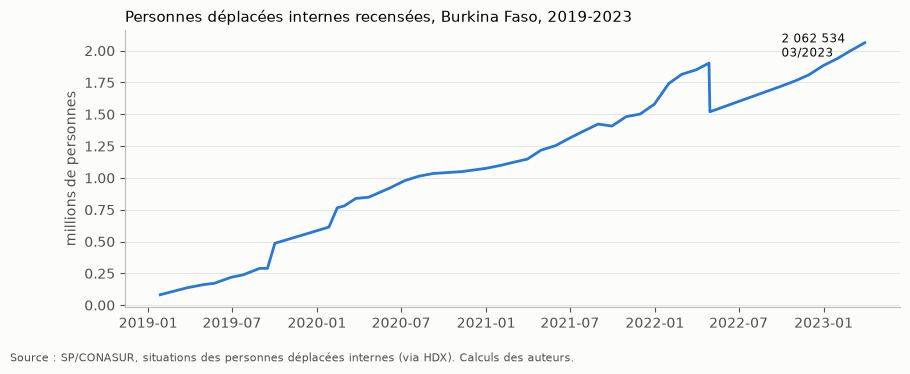

,deplaces,communes
date_situation,,
2022-11-30,1810105.0,299
2022-12-31,1882391.0,302
2023-01-31,1938792.0,302
2023-02-28,1999127.0,301
2023-03-31,2062534.0,303


In [20]:
pdi = res["fait_pdi_commune"]
serie = pdi.groupby("date_situation").agg(deplaces=("pdi_total", "sum"), communes=("commune_pcode", "nunique"))
serie.index = pd.to_datetime(serie.index)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(serie.index, serie["deplaces"] / 1e6, color="#2a78d6", linewidth=2)
ax.set_ylabel("millions de personnes"); ax.grid(axis="y", color="#e2e1dc", linewidth=0.6)
ax.set_title("Personnes déplacées internes recensées, Burkina Faso, 2019-2023", loc="left", fontsize=11)
dernier = serie.iloc[-1]
ax.annotate(f"{dernier['deplaces']:,.0f}".replace(",", " ") + f"\n{serie.index[-1]:%m/%Y}", (serie.index[-1], dernier["deplaces"] / 1e6),
            xytext=(-60, -10), textcoords="offset points", fontsize=8.5, color="#0b0b0b")
fig.text(0.01, -0.04, "Source : SP/CONASUR, situations des personnes déplacées internes (via HDX). Calculs des auteurs.", fontsize=8, color="#52514e")
plt.show()
serie.tail(5)

## 6. Métadonnées

`meta_tables` décrit chaque table ; `meta_variables` est le dictionnaire des variables. Un contrôle vérifie que toutes les tables et variables sont décrites.

In [21]:
res["meta_tables"]

,table,description,grain,cle,sources,periode,nb_lignes,nb_colonnes,date_production
0,commune,Contours et rattachements des 351 communes dans les deux découpages administratifs,commune,commune_pcode,"COD-AB (IGB, OCHA), août 2025 ; noms anciens : OpenStreetMap (HOT)",2025,351,15,2026-11-14
1,province,"Contours des 47 provinces du découpage de juillet 2025, obtenus en regroupant les communes",province (découpage 2025),province_pcode,"COD-AB, août 2025",2025,47,10,2026-11-14
2,region,Contours des 17 régions du découpage de juillet 2025,région (découpage 2025),region_pcode,"COD-AB, août 2025",2025,17,5,2026-11-14
3,province_ancienne,"Contours des 45 provinces de l'ancien découpage, reconstitués à partir des anciens P-codes des communes",province (ancien découpage),province_ancienne_pcode,"COD-AB, août 2025",avant juillet 2025,45,8,2026-11-14
4,region_ancienne,Contours des 13 régions de l'ancien découpage,région (ancien découpage),region_ancienne_pcode,"COD-AB, août 2025",avant juillet 2025,13,5,2026-11-14
5,ref_alias_nom,Correspondance entre les noms rencontrés dans les publications et les codes de l'ancien découpage,nom,nom_normalise,OpenStreetMap ; variantes relevées dans les annuaires DGESS,,72,5,2026-11-14
6,fait_flux_publie,"Taux de promotion, de redoublement et d'abandon publiés par la DGESS",édition × entité × classe × sexe × indicateur,"annee_publication, entite_pcode, niveau, sexe, indicateur","DGESS, annuaires statistiques du primaire, tableau I.8 (II.7 en 2017-2018)",éditions 2017-2018 à 2024-2025,22032,10,2026-11-14
7,fait_effectifs_editions,"Effectifs et redoublants par classe et sexe, tels que publiés dans chaque édition (historique sur une dizaine d'anné...",édition × année × entité × classe × sexe,"annee_publication, annee_scolaire, entite_pcode, niveau, sexe","DGESS, annuaires statistiques du primaire, tableau VIII.3 (IX.3 en 2017-2018)",2007-2008 à 2024-2025,101199,11,2026-11-14
8,fait_effectifs_retenus,"Effectifs et redoublants retenus : pour chaque année, la valeur de l'édition la plus récente qui la donne",année × entité × classe × sexe,"annee_scolaire, entite_pcode, niveau, sexe","DGESS, annuaires statistiques du primaire, tableau VIII.3",2007-2008 à 2024-2025,20720,12,2026-11-14
9,fait_offre_province,"Écoles, salles, groupes pédagogiques, maîtres et élèves par province et statut, avec les élèves par maître et par salle",année × entité × statut,"annee_scolaire, entite_pcode, statut","DGESS, annuaires statistiques du primaire, tableau I.1 (II.1 en 2017-2018)",2017-2018 à 2024-2025,1389,14,2026-11-14


In [22]:
res["meta_variables"][res["meta_variables"]["table"] == "fait_effectifs_retenus"]

,table,variable,type_donnee,unite,description
69,fait_effectifs_retenus,edition_retenue,texte,,Édition de l'annuaire dont la valeur est retenue (la plus récente)
70,fait_effectifs_retenus,annee_scolaire,texte,,Année scolaire à laquelle se rapporte la valeur
71,fait_effectifs_retenus,entite_pcode,texte,,"P-code de l'entité de l'ancien découpage (province, région, ou BF pour le pays)"
72,fait_effectifs_retenus,niveau_geo,texte,,Niveau géographique de l'entité
73,fait_effectifs_retenus,nom_source,texte,,Nom de l'entité tel qu'écrit dans la source
74,fait_effectifs_retenus,niveau,texte,,"Niveau : classe (CP1 à CM2, Total) dans les tables de faits ; niveau géographique dans l'alias"
75,fait_effectifs_retenus,sexe,texte,,"Sexe : G (garçons), F (filles), T (total)"
76,fait_effectifs_retenus,effectif,décimal,élèves,Nombre d'élèves inscrits
77,fait_effectifs_retenus,redoublants,décimal,élèves,Nombre d'élèves redoublants
78,fait_effectifs_retenus,source_fichier,texte,,Fichier d'origine remis par les organisateurs


## 7. Première carte : abandon apparent observé en 2023-2024

Taux calculé à partir des effectifs (cohorte reconstituée, CP1 à CM1, garçons et filles réunis), en additionnant les effectifs avant de diviser. Les valeurs négatives, conservées, signalent des arrivées nettes d'élèves. La carte suit le découpage de 2025 ; les deux provinces scindées (Soum, Tapoa) reçoivent le taux de l'ancienne province, ce que signalent les hachures.

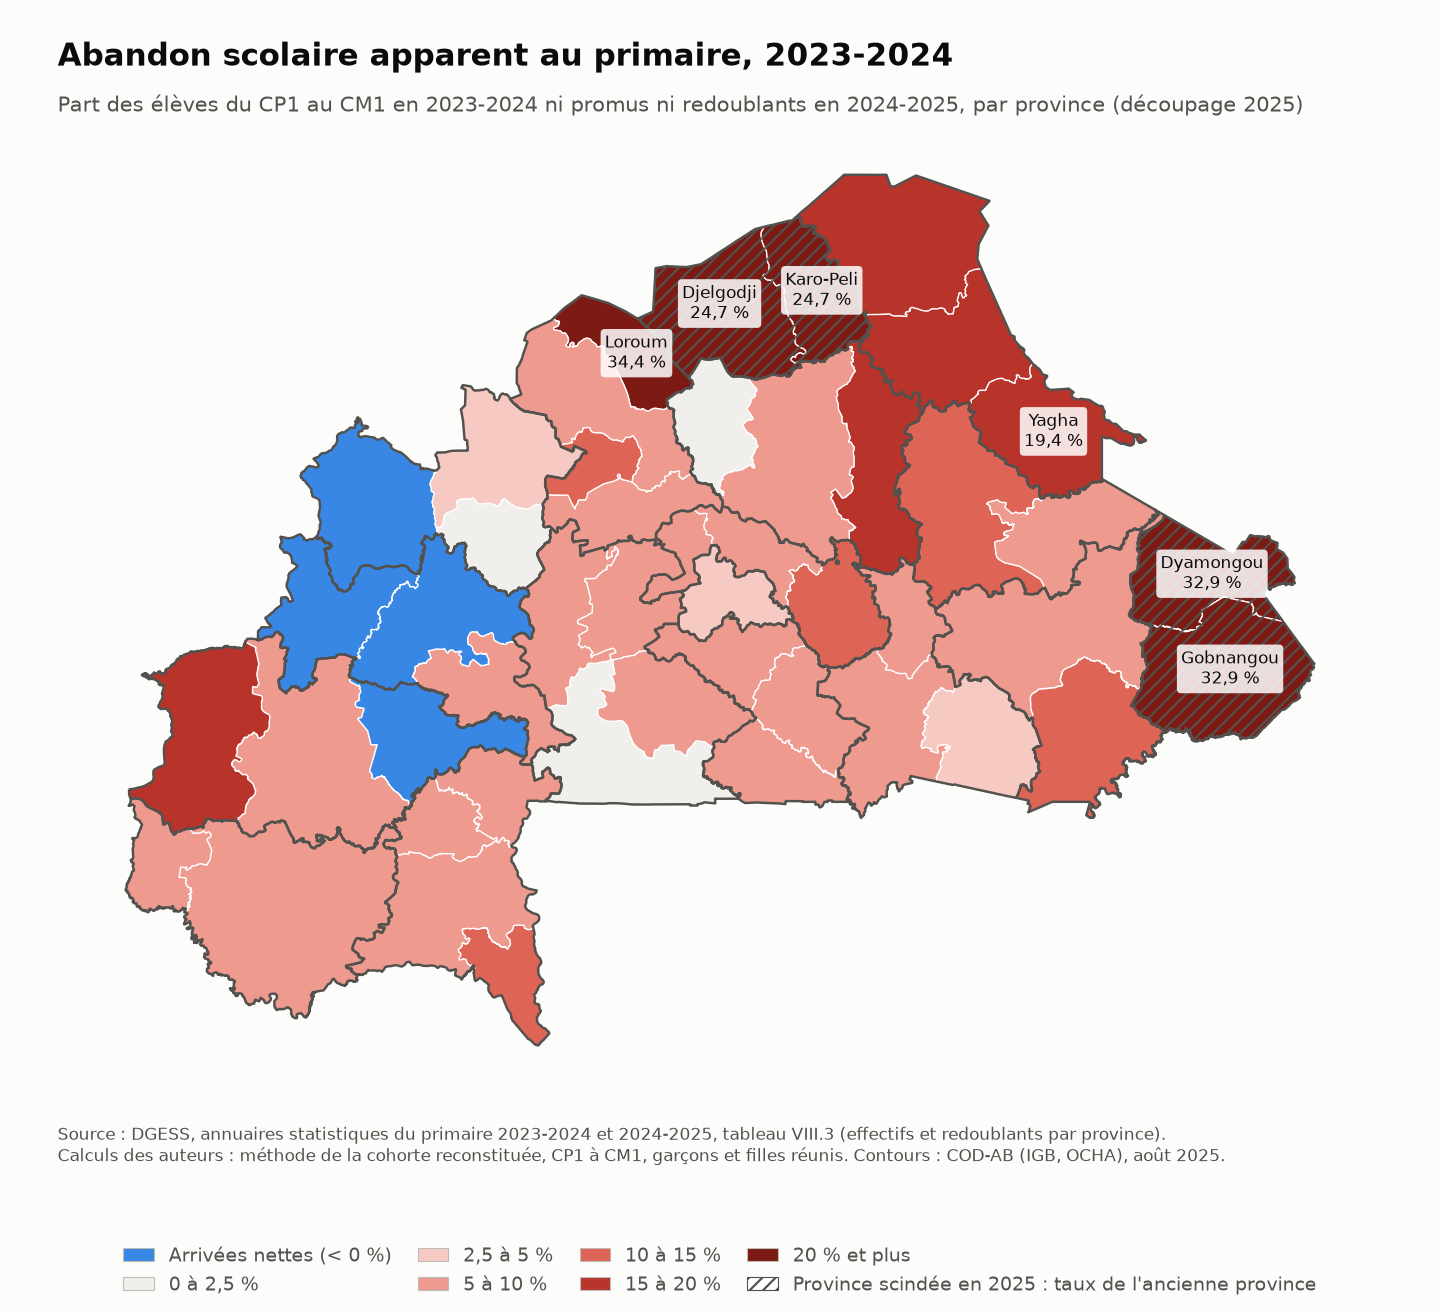

In [23]:
totaux = eff[(eff["niveau_geo"] == "province_ancienne") & (eff["sexe"] == "T")]
abandon = indicateurs.taux(indicateurs.flux_par_classe(totaux), ["entite_pcode", "annee_scolaire", "annee_suivante"])
derniere = abandon[abandon["annee_scolaire"] == "2023-2024"].set_index("entite_pcode")["taux_abandon"]
provinces = res["province"].set_index("province_pcode")
source = ("Source : DGESS, annuaires statistiques du primaire 2023-2024 et 2024-2025, tableau VIII.3 (effectifs et redoublants par province).\n"
          "Calculs des auteurs : méthode de la cohorte reconstituée, CP1 à CM1, garçons et filles réunis. Contours : COD-AB (IGB, OCHA), août 2025.")
chemin = cartes.carte_abandon(provinces, provinces["province_ancienne_pcode"].map(derniere),
                              "Abandon scolaire apparent au primaire, 2023-2024",
                              "Part des élèves du CP1 au CM1 en 2023-2024 ni promus ni redoublants en 2024-2025, par province (découpage 2025)",
                              source, config.FIGURES / "carte_abandon_observe_2023_2024.png", contours_regions=res["region"])
display(Image(filename=str(chemin), width=760))

In [24]:
(abandon[abandon["annee_scolaire"] == "2023-2024"]
 .merge(res["province_ancienne"][["province_ancienne_pcode", "province_ancienne_nom"]], left_on="entite_pcode", right_on="province_ancienne_pcode")
 .nlargest(8, "taux_abandon")[["province_ancienne_nom", "effectif_t", "abandons", "taux_abandon"]])

,province_ancienne_nom,effectif_t,abandons,taux_abandon
30,Loroum,18680.0,6416.0,34.35
26,Tapoa,13164.0,4325.0,32.85
39,Soum,11503.0,2840.0,24.69
40,Yagha,3608.0,699.0,19.37
37,Oudalan,15064.0,2814.0,18.68
38,Séno,22964.0,4205.0,18.31
13,Namentenga,24762.0,4255.0,17.18
28,Kénédougou,57277.0,9403.0,16.42


## 8. Dépôts au format du challenge

In [25]:
depot = exporter_nettoyage(version=1)
depot[["fichier_depose", "role"]]

,fichier_depose,role
0,EXX_02-nettoyage_D1_architect_base-sentinelle-scolaire-geopackage_v1.gpkg,architect
1,EXX_02-nettoyage_D1_architect_metadonnees-description-des-tables_v1.csv,architect
2,EXX_02-nettoyage_D1_architect_metadonnees-dictionnaire-des-variables_v1.csv,architect
3,EXX_02-nettoyage_D1_engineer_referentiel-communes-deux-decoupages_v1.csv,engineer
4,EXX_02-nettoyage_D1_engineer_referentiel-provinces-decoupage-2025_v1.csv,engineer
5,EXX_02-nettoyage_D1_engineer_referentiel-provinces-ancien-decoupage_v1.csv,engineer
6,EXX_02-nettoyage_D1_engineer_referentiel-regions-decoupage-2025_v1.csv,engineer
7,EXX_02-nettoyage_D1_engineer_referentiel-regions-ancien-decoupage_v1.csv,engineer
8,EXX_02-nettoyage_D1_engineer_alias-noms-provinces-regions_v1.csv,engineer
9,EXX_02-nettoyage_D1_engineer_taux-abandon-redoublement-publies-province-2017-2025-propre_v1.csv,engineer


## 9. Limites et suite

- L'abandon apparent mesure toutes les pertes nettes d'élèves d'une province, y compris les fermetures d'écoles et les départs de familles. Là où les effectifs varient de plus de 30 % en un an (fermetures ou réouvertures massives), il cesse d'être un taux d'abandon : ces cas seront repérés et traités à part à l'étape 03.
- Répartition par sexe de 2024-2025 inutilisable pour 31 provinces.
- Données ESU provinciales fiables seulement pour novembre 2021 à mai 2022 et octobre 2023 ; série régionale des fermetures jusqu'en mai 2023 ; déplacés internes jusqu'en mars 2023.
- Aucune donnée au niveau de l'école ou de l'élève.

Étape suivante (03) : panel province × année pour la modélisation, repérage des chocs d'effectifs, variables explicatives et dictionnaire du modèle.